# 🦠 SafeConnect: Forecasting COVID-19 Spread with Real-World Data

Can a country's **reported COVID-19 incidence over the next 14 days** be forecast from what is already known today, and does knowing what is happening in **neighbouring countries** help?

This notebook answers that with public data only:

- **Cases:** JHU CSSE COVID-19 time series (daily cumulative confirmed cases, Jan 2020 to Mar 2023)
- **Population:** World Bank, indicator `SP.POP.TOTL` (2020)
- **Network:** a geographic nearest-neighbour graph of countries, built from the JHU coordinates

**Approach.** Every country and every week becomes one observation. Features describe the past (last 14 days, the 14 days before, cumulative cases, population, neighbours); the target is the next 14 days. Models are trained on 2020 to mid-2021 and tested on mid-2021 to the end of 2022, so the test set is a genuinely unseen future that includes the Delta and Omicron waves. Every model is compared with a **persistence baseline**: "the next 14 days will look like the last 14".

> This is the revised version of a postgraduate pitch project. The original notebook (in Portuguese) is kept in [`archive/`](archive/) for reference; see the README for what changed and why.

## 1. Setup

In [1]:
import json
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression, Perceptron, SGDClassifier
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_score, r2_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
DATA, ASSETS = Path("data"), Path("assets")
DATA.mkdir(exist_ok=True)
ASSETS.mkdir(exist_ok=True)

# Chart style: light surface, recessive grid, colour-blind-safe series colours
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
})

def save(fig, name):
    fig.savefig(ASSETS / name, dpi=150, bbox_inches="tight")

## 2. Load the data

Local snapshots in `data/` are used when present; otherwise the files are downloaded from the original sources (useful in Google Colab).

In [2]:
JHU_URL = ("https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/"
           "csse_covid_19_time_series/time_series_covid19_confirmed_global.csv")
WB_API = "https://api.worldbank.org/v2/{}?format=json&per_page=20000"

jhu_path = DATA / "time_series_covid19_confirmed_global.csv"
if not jhu_path.exists():
    pd.read_csv(JHU_URL).to_csv(jhu_path, index=False)

pop_path = DATA / "world_bank_population.csv"
if not pop_path.exists():
    def wb(path):
        with urlopen(WB_API.format(path)) as response:
            return json.load(response)[1]
    real = {c["iso2Code"] for c in wb("country") if c["region"]["value"] != "Aggregates"}
    rows = [(p["countryiso3code"], p["country"]["value"], int(p["date"]), p["value"])
            for p in wb("country/all/indicator/SP.POP.TOTL") if p["country"]["id"] in real]
    pd.DataFrame(rows, columns=["iso3", "country", "year", "population"]).dropna().to_csv(pop_path, index=False)

raw = pd.read_csv(jhu_path)
wb_pop = pd.read_csv(pop_path)
population_2020 = wb_pop[wb_pop["year"] == 2020].set_index("country")["population"]

date_cols = raw.columns[4:]
print(f"JHU: {len(raw)} rows (countries and provinces), {len(date_cols)} days from {date_cols[0]} to {date_cols[-1]}")
print(f"World Bank: population in 2020 for {len(population_2020)} economies")
raw.head(3)

JHU: 289 rows (countries and provinces), 1143 days from 1/22/20 to 3/9/23
World Bank: population in 2020 for 217 economies


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,209322,209340,209358,209362,209369,209390,209406,209436,209451,209451
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,334391,334408,334408,334427,334427,334427,334427,334427,334443,334457
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,271441,271448,271463,271469,271469,271477,271477,271490,271494,271496


## 3. Clean and align the two sources

- **One series per country.** When JHU has a national row, it is used alone (this leaves out overseas territories, which the World Bank counts separately); otherwise the provinces are summed (Australia, Canada, China). Hong Kong and Macau are separate economies in the World Bank data, so they become their own series.
- **Country names.** JHU and the World Bank spell 27 names differently (`US` vs `United States`, `Korea, South` vs `Korea, Rep.`…); a mapping fixes them instead of silently dropping large countries.
- **Exclusions.** Entries without World Bank population (cruise ships, Olympic Games, Antarctica, Holy See, Taiwan, Nauru) and micro-states under 100,000 inhabitants, where a handful of cases swings per-capita rates.
- **Corrections.** Cumulative counts occasionally go down after data corrections; a running maximum keeps them monotonic.

In [3]:
NAME_MAP = {
    "Bahamas": "Bahamas, The", "Brunei": "Brunei Darussalam", "Burma": "Myanmar",
    "Congo (Brazzaville)": "Congo, Rep.", "Congo (Kinshasa)": "Congo, Dem. Rep.",
    "Egypt": "Egypt, Arab Rep.", "Gambia": "Gambia, The", "Iran": "Iran, Islamic Rep.",
    "Korea, North": "Korea, Dem. People's Rep.", "Korea, South": "Korea, Rep.",
    "Kyrgyzstan": "Kyrgyz Republic", "Laos": "Lao PDR", "Micronesia": "Micronesia, Fed. Sts.",
    "Russia": "Russian Federation", "Saint Kitts and Nevis": "St. Kitts and Nevis",
    "Saint Lucia": "St. Lucia", "Saint Vincent and the Grenadines": "St. Vincent and the Grenadines",
    "Slovakia": "Slovak Republic", "Somalia": "Somalia, Fed. Rep.", "Syria": "Syrian Arab Republic",
    "Turkey": "Turkiye", "US": "United States", "Venezuela": "Venezuela, RB", "Vietnam": "Viet Nam",
    "Yemen": "Yemen, Rep.", "Hong Kong": "Hong Kong SAR, China", "Macau": "Macao SAR, China",
}

jhu = raw.copy()
sar = jhu["Country/Region"].eq("China") & jhu["Province/State"].isin(["Hong Kong", "Macau"])
jhu.loc[sar, "Country/Region"] = jhu.loc[sar, "Province/State"]
jhu.loc[sar, "Province/State"] = np.nan

has_national_row = jhu.loc[jhu["Province/State"].isna(), "Country/Region"].unique()
jhu = jhu[jhu["Province/State"].isna() | ~jhu["Country/Region"].isin(has_national_row)]

cum = jhu.groupby("Country/Region")[list(date_cols)].sum().T
cum.index = pd.to_datetime(cum.index, format="%m/%d/%y")
coords = jhu[jhu["Lat"].fillna(0) != 0].groupby("Country/Region")[["Lat", "Long"]].mean()

wb_name = {c: NAME_MAP.get(c, c) for c in cum.columns}
no_population = sorted(c for c in cum.columns if wb_name[c] not in population_2020.index)
population = pd.Series({c: population_2020[wb_name[c]] for c in cum.columns if c not in no_population})
too_small = sorted(population[population < 100_000].index)
countries = sorted(population[population >= 100_000].index)

population = population[countries]
cum = cum[countries].cummax()
coords = coords.loc[countries]

print(f"Countries kept: {len(countries)}")
print(f"No World Bank population ({len(no_population)}): {', '.join(no_population)}")
print(f"Under 100,000 inhabitants ({len(too_small)}): {', '.join(too_small)}")

Countries kept: 184
No World Bank population (8): Antarctica, Diamond Princess, Holy See, MS Zaandam, Nauru, Summer Olympics 2020, Taiwan*, Winter Olympics 2022
Under 100,000 inhabitants (11): Andorra, Antigua and Barbuda, Dominica, Liechtenstein, Marshall Islands, Monaco, Palau, Saint Kitts and Nevis, San Marino, Seychelles, Tuvalu


## 4. The pandemic in one chart

The 14-day incidence per 100,000 inhabitants, summed over the countries kept. The shaded areas show which period trains the models and which one tests them.

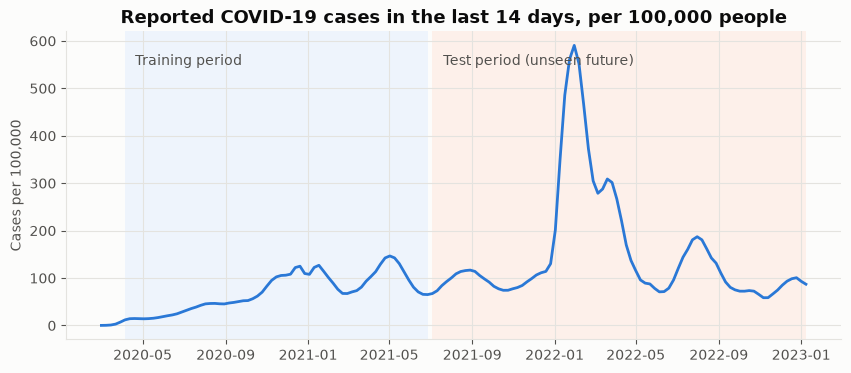

In [4]:
TRAIN_END, TEST_START = pd.Timestamp("2021-06-13"), pd.Timestamp("2021-07-04")
weekly = cum.resample("W-SUN").last()
world_inc = (weekly.sum(axis=1).diff(2).clip(lower=0) / population.sum() * 1e5).loc["2020-03-01":"2023-01-08"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(pd.Timestamp("2020-04-05"), TRAIN_END + pd.Timedelta(days=14), color="#eef4fc", lw=0)
ax.axvspan(TEST_START, pd.Timestamp("2023-01-08"), color="#fdf0ea", lw=0)
ax.plot(world_inc.index, world_inc.values, color=BLUE)
ax.text(pd.Timestamp("2020-04-20"), world_inc.max() * 0.93, "Training period", color=MUTED)
ax.text(pd.Timestamp("2021-07-20"), world_inc.max() * 0.93, "Test period (unseen future)", color=MUTED)
ax.set_title("Reported COVID-19 cases in the last 14 days, per 100,000 people")
ax.set_ylabel("Cases per 100,000")
save(fig, "global_incidence.png")
plt.show()

## 5. Network science: a geographic country network

Respiratory epidemics spread along human contact, and neighbouring countries share borders, trade and travel. Travel-flow data is not public at this granularity, so the network uses **geography as a proxy**: each country is linked to its **5 nearest countries** (great-circle distance between the JHU coordinates), and the links are undirected.

Unlike a complete graph, where every country has the same centrality, this network has structure: some countries sit on bridges between regions (high **betweenness**), others in dense clusters.

In [5]:
K = 5
lat, lon = np.radians(coords["Lat"].to_numpy()), np.radians(coords["Long"].to_numpy())
hav = (np.sin((lat[:, None] - lat[None, :]) / 2) ** 2
       + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin((lon[:, None] - lon[None, :]) / 2) ** 2)
dist_km = 2 * 6371 * np.arcsin(np.sqrt(hav))

G = nx.Graph()
G.add_nodes_from(countries)
for i, country in enumerate(countries):
    for j in np.argsort(dist_km[i])[1:K + 1]:
        G.add_edge(country, countries[j], km=dist_km[i, j])

degree_c = nx.degree_centrality(G)
betweenness_c = nx.betweenness_centrality(G)
degrees = dict(G.degree)
print(f"Nodes: {G.number_of_nodes()} | edges: {G.number_of_edges()} | connected components: {nx.number_connected_components(G)}")
print(f"Degree: min {min(degrees.values())}, median {np.median(list(degrees.values())):.0f}, max {max(degrees.values())}")
top_bridges = pd.Series(betweenness_c).sort_values(ascending=False).head(8)
print("\nCountries bridging regions (highest betweenness centrality):")
print(top_bridges.round(3).to_string())

Nodes: 184 | edges: 582 | connected components: 1
Degree: min 5, median 6, max 10

Countries bridging regions (highest betweenness centrality):
Iceland     0.306
Algeria     0.292
Niger       0.290
Canada      0.283
Chad        0.277
Portugal    0.271
Ireland     0.266
Libya       0.255


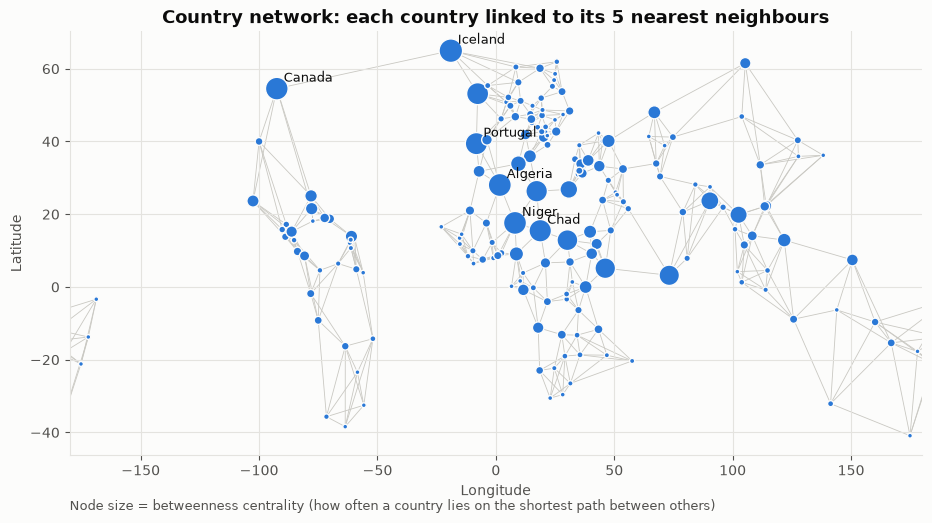

In [6]:
fig, ax = plt.subplots(figsize=(11, 5.5))
edge_style = dict(color="#c9c8c2", lw=0.6, zorder=1)
for a, b in G.edges:
    (x1, y1), (x2, y2) = coords.loc[a].to_numpy()[::-1], coords.loc[b].to_numpy()[::-1]
    if abs(x2 - x1) <= 180:
        ax.plot([x1, x2], [y1, y2], **edge_style)
    else:  # the shortest path crosses the date line: draw it as two segments at the map edges
        if x1 > x2:
            x1, y1, x2, y2 = x2, y2, x1, y1
        y_edge = y1 + (y2 - y1) * (-180 - x1) / ((x2 - 360) - x1)
        ax.plot([x1, -180], [y1, y_edge], **edge_style)
        ax.plot([180, x2], [y_edge, y2], **edge_style)
ax.set_xlim(-180, 180)
sizes = 12 + 900 * np.array([betweenness_c[c] for c in countries])
ax.scatter(coords["Long"], coords["Lat"], s=sizes, color=BLUE, edgecolor="#fcfcfb", linewidth=1, zorder=2)
for country in top_bridges.index[:6]:
    ax.annotate(country, (coords.at[country, "Long"], coords.at[country, "Lat"]), xytext=(5, 5),
                textcoords="offset points", fontsize=9, color=INK)
ax.set_title("Country network: each country linked to its 5 nearest neighbours")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.text(0, -0.13, "Node size = betweenness centrality (how often a country lies on the shortest path between others)",
        transform=ax.transAxes, color=MUTED, fontsize=9)
save(fig, "network_map.png")
plt.show()

## 6. Build the modelling panel

One row per **country × reference date**, every 7 days from April 2020 to December 2022. All features use information available **on the reference date**; the target is the following 14 days.

| Feature | Meaning |
|---|---|
| `log_inc_last` | log(1 + cases per 100k in the last 14 days) |
| `log_inc_prev` | log(1 + cases per 100k in the 14 days before that) |
| `growth` | `log_inc_last − log_inc_prev` (is the curve rising or falling?) |
| `log_cum` | log(1 + cumulative cases per 100k): past exposure and testing intensity |
| `log_pop` | log10(population) |
| `nbr_log_inc_last` | mean `log_inc_last` of the country's network neighbours |
| `nbr_growth` | mean `growth` of the neighbours |
| `degree_c`, `betweenness_c` | network centrality of the country |

**Target:** `y = log(1 + cases per 100k in the next 14 days)`. Working in log space treats a jump from 10 to 20 like one from 1,000 to 2,000, so large countries do not dominate the error. Rows before a country reached 100 cumulative cases are dropped.

In [7]:
per_100k = 1e5 / population
day = pd.Timedelta(days=1)

def cases_between(t0, t1):
    return (cum.loc[t1] - cum.loc[t0]).clip(lower=0) * per_100k

frames = []
for T in pd.date_range("2020-04-05", "2022-12-25", freq="7D"):
    last, prev, nxt = cases_between(T - 14 * day, T), cases_between(T - 28 * day, T - 14 * day), cases_between(T, T + 14 * day)
    f = pd.DataFrame({
        "country": countries, "date": T,
        "log_inc_last": np.log1p(last.to_numpy()), "log_inc_prev": np.log1p(prev.to_numpy()),
        "log_cum": np.log1p((cum.loc[T] * per_100k).to_numpy()), "log_pop": np.log10(population.to_numpy()),
        "cum_cases": cum.loc[T].to_numpy(), "inc_last": last.to_numpy(), "inc_next": nxt.to_numpy(),
    })
    f["growth"] = f["log_inc_last"] - f["log_inc_prev"]
    level, trend = f.set_index("country")["log_inc_last"], f.set_index("country")["growth"]
    f["nbr_log_inc_last"] = [level[list(G[c])].mean() for c in countries]
    f["nbr_growth"] = [trend[list(G[c])].mean() for c in countries]
    f["degree_c"] = [degree_c[c] for c in countries]
    f["betweenness_c"] = [betweenness_c[c] for c in countries]
    frames.append(f)

panel = pd.concat(frames, ignore_index=True)
panel = panel[panel["cum_cases"] >= 100].reset_index(drop=True)
panel["y"] = np.log1p(panel["inc_next"])

BASE = ["log_inc_last", "log_inc_prev", "growth", "log_cum", "log_pop"]
NETWORK = BASE + ["nbr_log_inc_last", "nbr_growth", "degree_c", "betweenness_c"]
print(f"Panel: {len(panel):,} rows, {panel['country'].nunique()} countries, {panel['date'].nunique()} reference dates")
panel[["country", "date"] + NETWORK + ["y"]].sample(5, random_state=SEED)

Panel: 24,838 rows, 183 countries, 143 reference dates


,country,date,log_inc_last,log_inc_prev,growth,log_cum,log_pop,nbr_log_inc_last,nbr_growth,degree_c,betweenness_c,y
14218,Cote d'Ivoire,2021-11-14,0.553936,0.639596,-0.085660,5.364700,7.461130,0.546802,-0.012981,0.038251,0.021553,0.519565
23079,Honduras,2022-10-23,1.435488,1.444851,-0.009363,8.415571,7.005165,1.967790,-0.549667,0.054645,0.062716,1.116913
20004,Malaysia,2022-06-26,4.506485,4.213327,0.293159,9.506484,7.530066,3.792872,0.171972,0.032787,0.000400,4.762126
8483,Mauritius,2021-03-28,2.717265,2.001214,0.716051,4.244482,6.102439,2.019163,-0.292907,0.027322,0.002347,3.225667
16688,Congo (Kinshasa),2022-02-20,0.290828,0.823411,-0.532583,4.504463,7.982226,1.375386,-0.932693,0.032787,0.025174,0.287708


## 7. Time-based train/test split

A random split would leak the future into training (next week's row of the same country is almost identical). Instead:

- **Train:** reference dates up to 13 June 2021 (their 14-day target windows end by 27 June 2021)
- **Test:** reference dates from 4 July 2021 to 25 December 2022: Delta, Omicron and the end of mass testing

In [8]:
train = panel[panel["date"] <= TRAIN_END].sort_values("date").reset_index(drop=True)
test = panel[panel["date"] >= TEST_START].reset_index(drop=True)
print(f"Train: {len(train):,} rows ({train['date'].min():%Y-%m-%d} to {train['date'].max():%Y-%m-%d})")
print(f"Test:  {len(test):,} rows ({test['date'].min():%Y-%m-%d} to {test['date'].max():%Y-%m-%d})")

Train: 10,482 rows (2020-04-05 to 2021-06-13)
Test:  14,004 rows (2021-07-04 to 2022-12-25)


## 8. Regression: forecasting the next 14 days

Models, from simplest to most flexible, each with and without the network features. The MLP (a small neural network) is tuned with **time-series cross-validation** inside the training period, so the test period is never used for choices.

Metrics are on the log scale. `Error factor` = exp(MAE): a value of 1.65 means the forecast is typically within a factor of about 1.65 of the actual incidence.

In [9]:
def regression_row(name, pred):
    mae = mean_absolute_error(test["y"], pred)
    return {"Model": name, "MAE": mae, "RMSE": mean_squared_error(test["y"], pred) ** 0.5,
            "R²": r2_score(test["y"], pred), "Error factor": np.exp(mae)}

tscv = TimeSeriesSplit(n_splits=3)
mlp_search = GridSearchCV(
    make_pipeline(StandardScaler(), MLPRegressor(max_iter=1000, early_stopping=True, random_state=SEED)),
    {"mlpregressor__hidden_layer_sizes": [(32,), (64, 32)], "mlpregressor__alpha": [1e-4, 1e-2]},
    cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1)

regressors = {
    "Linear regression": (LinearRegression(), BASE),
    "Linear regression + network": (LinearRegression(), NETWORK),
    "Random forest": (RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED), BASE),
    "Random forest + network": (RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED), NETWORK),
    "MLP + network (tuned)": (mlp_search, NETWORK),
}

reg_results = [regression_row("Persistence baseline", test["log_inc_last"])]
reg_pred = {"Persistence baseline": test["log_inc_last"].to_numpy()}
for name, (model, feats) in regressors.items():
    model.fit(train[feats], train["y"])
    reg_pred[name] = model.predict(test[feats])
    reg_results.append(regression_row(name, reg_pred[name]))

print("MLP best parameters:", mlp_search.best_params_)
reg_table = pd.DataFrame(reg_results).set_index("Model").round(3)
reg_table

MLP best parameters: {'mlpregressor__alpha': 0.0001, 'mlpregressor__hidden_layer_sizes': (32,)}


,MAE,RMSE,R²,Error factor
Model,,,,
Persistence baseline,0.533,0.848,0.878,1.705
Linear regression,0.515,0.846,0.878,1.674
Linear regression + network,0.501,0.821,0.885,1.650
Random forest,0.525,0.818,0.886,1.690
Random forest + network,0.516,0.806,0.889,1.676
MLP + network (tuned),0.492,0.776,0.897,1.636


Best model by MAE: MLP + network (tuned) (7.7% lower MAE than the persistence baseline)


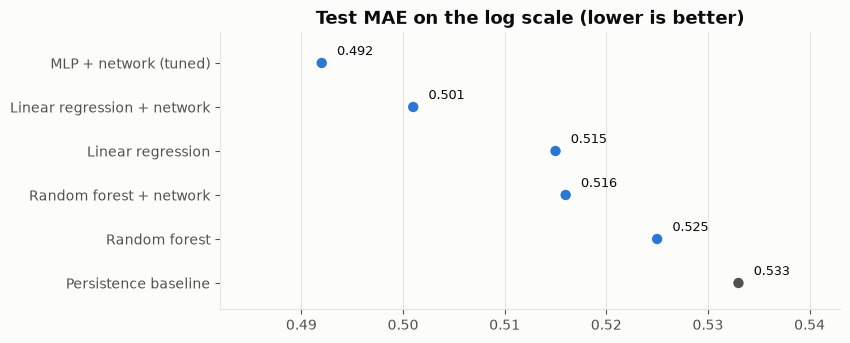

In [10]:
best_reg = reg_table["MAE"].drop("Persistence baseline").idxmin()
gain = 1 - reg_table.at[best_reg, "MAE"] / reg_table.at["Persistence baseline", "MAE"]
print(f"Best model by MAE: {best_reg} ({gain:.1%} lower MAE than the persistence baseline)")

fig, ax = plt.subplots(figsize=(8, 3.6))
order = reg_table["MAE"].sort_values(ascending=False)
colors = [GRAY if m == "Persistence baseline" else BLUE for m in order.index]
ax.scatter(order.values, order.index, s=90, color=colors, edgecolor="#fcfcfb", linewidth=2, zorder=3)
for y, v in enumerate(order.values):
    ax.text(v + 0.0015, y + 0.18, f"{v:.3f}", color=INK, fontsize=9)
ax.set_xlim(order.min() - 0.01, order.max() + 0.01)
ax.set_ylim(-0.6, len(order) - 0.3)
ax.set_title("Test MAE on the log scale (lower is better)")
ax.grid(axis="y", visible=False)
save(fig, "regression_mae.png")
plt.show()

### Forecasts for four countries

Actual 14-day incidence compared with the persistence baseline and the best model by MAE, over the test period. The persistence baseline is, by construction, the actual curve shifted two weeks to the right; a useful model turns earlier.

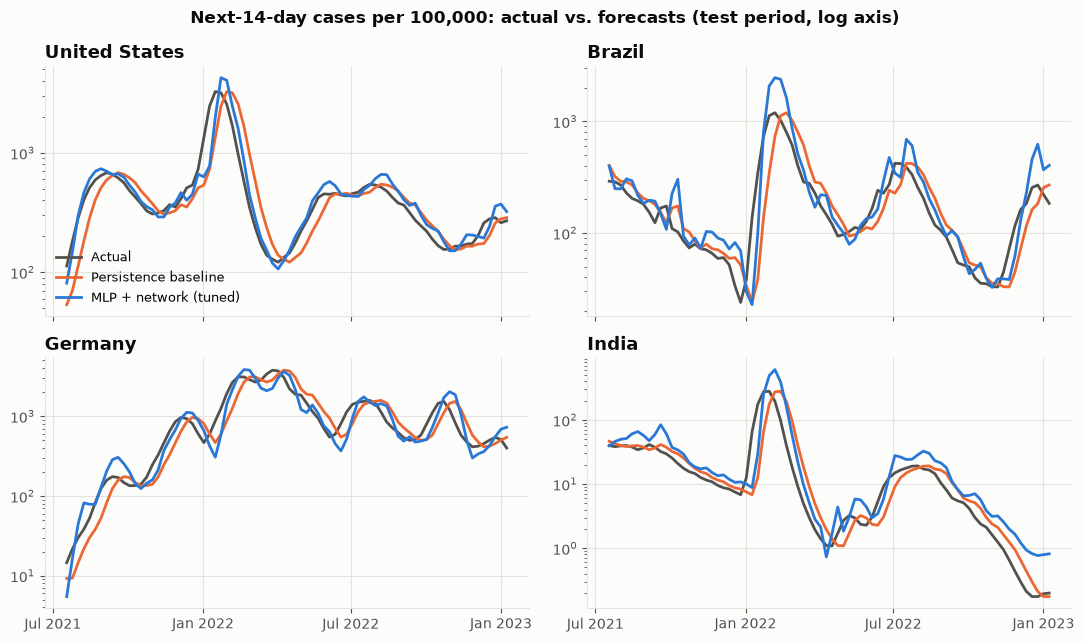

In [11]:
examples = ["US", "Brazil", "Germany", "India"]
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for ax, country in zip(axes.flat, examples):
    rows = test["country"].eq(country).to_numpy()
    d = test.loc[rows, "date"] + 14 * day  # forecasts refer to the window ending 14 days later
    ax.plot(d, test.loc[rows, "inc_next"], color=GRAY, label="Actual")
    ax.plot(d, np.expm1(reg_pred["Persistence baseline"][rows]), color=ORANGE, label="Persistence baseline")
    ax.plot(d, np.expm1(reg_pred[best_reg][rows]), color=BLUE, label=best_reg)
    ax.set_yscale("log")
    ax.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %Y"))
    ax.set_title({"US": "United States"}.get(country, country), loc="left")
axes[0, 0].legend(loc="lower left", fontsize=9)
fig.suptitle("Next-14-day cases per 100,000: actual vs. forecasts (test period, log axis)", fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "forecast_examples.png")
plt.show()

### Why the random forest underestimates Omicron

A random forest predicts averages of training targets: it can never exceed the training range, and where training rows are scarce (very high incidence was rare before mid-2021) it stays well below it. Omicron pushed many countries into that territory. Linear and neural-network models can extrapolate, which is why they handle the test period better.

In [12]:
for level in (1_000, 2_000):
    print(f"Rows above {level:,} per 100k: train {(train['inc_next'] > level).mean():.1%} | test {(test['inc_next'] > level).mean():.1%}")
cap = train["y"].max()
over = test["y"] > cap
print(f"Highest next-14-day incidence in training: {np.expm1(cap):,.0f} per 100k")
print(f"Test rows above that level: {over.sum():,} ({over.mean():.1%})")
for name in ["Random forest + network", "Linear regression + network", "MLP + network (tuned)"]:
    print(f"  {name:30s} max forecast {np.expm1(reg_pred[name].max()):>9,.0f} | MAE on those rows {mean_absolute_error(test.loc[over, 'y'], reg_pred[name][over.to_numpy()]):.3f}")

Rows above 1,000 per 100k: train 1.3% | test 8.3%
Rows above 2,000 per 100k: train 0.1% | test 3.3%
Highest next-14-day incidence in training: 4,005 per 100k
Test rows above that level: 154 (1.1%)
  Random forest + network        max forecast     1,846 | MAE on those rows 1.611
  Linear regression + network    max forecast    16,332 | MAE on those rows 0.516
  MLP + network (tuned)          max forecast     9,201 | MAE on those rows 0.583


## 9. Classification: will a country be in the "red zone"?

For decisions such as travel rules or hospital preparedness, the question is often binary. Here a country is **high incidence** when it reports **more than 150 cases per 100,000 in the next 14 days**, the level above which the EU's 2020 travel-coordination map ([Council Recommendation (EU) 2020/1475](https://eur-lex.europa.eu/eli/reco/2020/1475/2021-02-02/eng)) classified a region as red regardless of test positivity.

The Perceptron and Adaline are the single-neuron classifiers from the course (Adaline is fitted as `SGDClassifier` with squared loss); logistic regression, random forest and an MLP complete the set. The baseline predicts "red" if the last 14 days were already above 150.

In [13]:
THRESHOLD = 150
y_train_cls = (train["inc_next"] > THRESHOLD).astype(int)
y_test_cls = (test["inc_next"] > THRESHOLD).astype(int)
print(f"High-incidence share: train {y_train_cls.mean():.1%} | test {y_test_cls.mean():.1%}")

def classification_row(name, y_pred, score=None):
    return {"Model": name, "Balanced accuracy": balanced_accuracy_score(y_test_cls, y_pred),
            "Precision": precision_score(y_test_cls, y_pred), "Recall": recall_score(y_test_cls, y_pred),
            "F1": f1_score(y_test_cls, y_pred), "ROC AUC": roc_auc_score(y_test_cls, score) if score is not None else np.nan}

scaled = lambda clf: make_pipeline(StandardScaler(), clf)
classifiers = {
    "Perceptron": (scaled(Perceptron(class_weight="balanced", random_state=SEED)), BASE),
    "Adaline (SGD, squared loss)": (scaled(SGDClassifier(loss="squared_error", class_weight="balanced", random_state=SEED)), BASE),
    "Logistic regression": (scaled(LogisticRegression(class_weight="balanced", max_iter=2000)), BASE),
    "Logistic regression + network": (scaled(LogisticRegression(class_weight="balanced", max_iter=2000)), NETWORK),
    "Random forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=SEED), BASE),
    "Random forest + network": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=SEED), NETWORK),
    "MLP + network": (scaled(MLPClassifier(hidden_layer_sizes=(32,), alpha=1e-2, max_iter=1000, early_stopping=True, random_state=SEED)), NETWORK),
}

cls_results = [classification_row("Persistence baseline", (test["inc_last"] > THRESHOLD).astype(int))]
cls_pred = {}
for name, (model, feats) in classifiers.items():
    model.fit(train[feats], y_train_cls)
    score = model.predict_proba(test[feats])[:, 1] if hasattr(model, "predict_proba") else model.decision_function(test[feats])
    cls_pred[name] = model.predict(test[feats])
    cls_results.append(classification_row(name, cls_pred[name], score))

cls_table = pd.DataFrame(cls_results).set_index("Model").round(3)
cls_table

High-incidence share: train 22.9% | test 32.1%


,Balanced accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Persistence baseline,0.907,0.871,0.874,0.873,NaN
Perceptron,0.909,0.761,0.961,0.849,0.968
"Adaline (SGD, squared loss)",0.881,0.680,0.981,0.803,0.970
Logistic regression,0.925,0.820,0.949,0.880,0.973
Logistic regression + network,0.928,0.825,0.952,0.884,0.973
Random forest,0.928,0.863,0.925,0.893,0.977
Random forest + network,0.930,0.870,0.925,0.897,0.978
MLP + network,0.912,0.904,0.867,0.885,0.972


Best classifier by balanced accuracy: Random forest + network


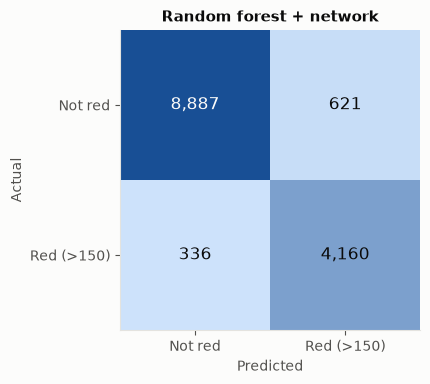

In [14]:
best_cls = cls_table["Balanced accuracy"].drop("Persistence baseline").idxmax()
cm = confusion_matrix(y_test_cls, cls_pred[best_cls])
print(f"Best classifier by balanced accuracy: {best_cls}")

fig, ax = plt.subplots(figsize=(4.6, 3.9))
ax.imshow(cm, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#184f95"]))
labels = ["Not red", "Red (>150)"]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="#fcfcfb" if cm[i, j] > cm.max() / 2 else INK, fontsize=12)
ax.set_xticks([0, 1], labels); ax.set_yticks([0, 1], labels)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.grid(False)
ax.set_title(best_cls, fontsize=11)
save(fig, "confusion_matrix.png")
plt.show()

## 10. Early warning: will incidence rise?

A harder question: will the next 14 days be **at least 20% higher** than the last 14? Only rows with at least 10 cases per 100k in the last 14 days are used, since tiny counts make percentage changes meaningless. The baseline is momentum: "it will rise if it rose in the last period".

In [15]:
active_train = train[train["inc_last"] >= 10]
active_test = test[test["inc_last"] >= 10]
y_tr = (active_train["inc_next"] >= 1.2 * active_train["inc_last"]).astype(int)
y_te = (active_test["inc_next"] >= 1.2 * active_test["inc_last"]).astype(int)
print(f"Rising share: train {y_tr.mean():.1%} | test {y_te.mean():.1%} | test rows {len(active_test):,}")

momentum = (active_test["growth"] > 0).astype(int)
rows = [{"Model": "Momentum baseline", "Balanced accuracy": balanced_accuracy_score(y_te, momentum),
         "F1": f1_score(y_te, momentum), "ROC AUC": np.nan}]
for name, model, feats in [
    ("Logistic regression", scaled(LogisticRegression(class_weight="balanced", max_iter=2000)), BASE),
    ("Logistic regression + network", scaled(LogisticRegression(class_weight="balanced", max_iter=2000)), NETWORK),
    ("Random forest + network", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=SEED), NETWORK),
]:
    model.fit(active_train[feats], y_tr)
    p = model.predict_proba(active_test[feats])[:, 1]
    rows.append({"Model": name, "Balanced accuracy": balanced_accuracy_score(y_te, p >= 0.5),
                 "F1": f1_score(y_te, p >= 0.5), "ROC AUC": roc_auc_score(y_te, p)})
rise_table = pd.DataFrame(rows).set_index("Model").round(3)
rise_table

Rising share: train 33.6% | test 31.0% | test rows 8,813


,Balanced accuracy,F1,ROC AUC
Model,,,
Momentum baseline,0.709,0.603,NaN
Logistic regression,0.722,0.617,0.776
Logistic regression + network,0.719,0.613,0.777
Random forest + network,0.703,0.590,0.775


## 11. What drives the forecast?

Permutation importance on the **test set** for the random forest with network features: how much the MAE grows when one feature is shuffled.

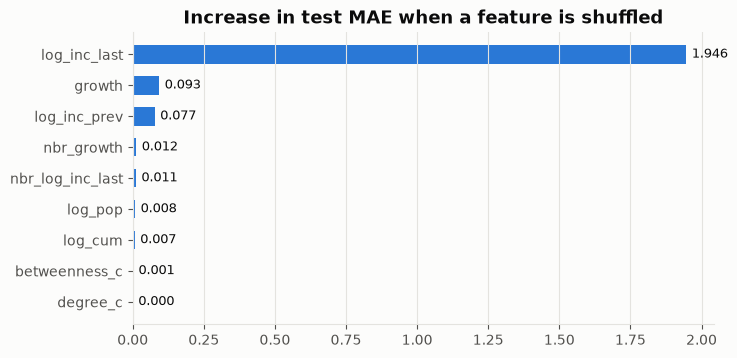

log_inc_last        1.9464
growth              0.0930
log_inc_prev        0.0771
nbr_growth          0.0125
nbr_log_inc_last    0.0111
log_pop             0.0084
log_cum             0.0069
betweenness_c       0.0008
degree_c            0.0001
dtype: float64

In [16]:
rf_net = regressors["Random forest + network"][0]
imp = permutation_importance(rf_net, test[NETWORK], test["y"], scoring="neg_mean_absolute_error",
                             n_repeats=5, random_state=SEED, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=NETWORK).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
for y, v in enumerate(importance.values):
    ax.text(v + importance.max() * 0.01, y, f"{v:.3f}", va="center", color=INK, fontsize=9)
ax.set_title("Increase in test MAE when a feature is shuffled")
ax.grid(axis="y", visible=False)
save(fig, "feature_importance.png")
plt.show()
importance.sort_values(ascending=False).round(4)

## 12. Summary

In [17]:
summary = {
    "Countries": len(countries),
    "Panel rows (train / test)": f"{len(train):,} / {len(test):,}",
    "Persistence baseline MAE": reg_table.at["Persistence baseline", "MAE"],
    f"Best regression MAE ({best_reg})": reg_table.at[best_reg, "MAE"],
    "Best regression R²": reg_table["R²"].max(),
    "Red-zone baseline balanced accuracy": cls_table.at["Persistence baseline", "Balanced accuracy"],
    f"Best red-zone balanced accuracy ({best_cls})": cls_table.at[best_cls, "Balanced accuracy"],
    "Best red-zone ROC AUC": cls_table["ROC AUC"].max(),
}
pd.Series(summary, name="value").to_frame()

,value
Countries,184
Panel rows (train / test),"10,482 / 14,004"
Persistence baseline MAE,0.533
Best regression MAE (MLP + network (tuned)),0.492
Best regression R²,0.897
Red-zone baseline balanced accuracy,0.907
Best red-zone balanced accuracy (Random forest + network),0.93
Best red-zone ROC AUC,0.978


**Conclusions** (written from the outputs above)

- **The persistence baseline is strong** (R² 0.878 on the log scale): incidence changes slowly compared with the differences between countries, so any claim of predictive power has to beat it.
- **The best regression model, an MLP with network features tuned by time-series cross-validation, cuts the MAE by 7.7%** (0.533 → 0.492) and reaches R² 0.897. Network features improved both the linear model (0.515 → 0.501) and the random forest (0.525 → 0.516).
- **What matters is what neighbours are going through, not network position:** in the permutation importance, the neighbours' growth and incidence rank right after the country's own history, while degree and betweenness centrality add almost nothing.
- **Random forests cannot extrapolate:** where Omicron pushed incidence above anything seen in training, the random forest's MAE (1.61) is about three times that of the linear and neural models. The forecast charts also show the MLP overshooting some sharp peaks (Brazil and India, January 2022).
- **Red-zone classification (> 150 per 100k in 14 days):** the random forest with network features reaches a balanced accuracy of 0.930 and ROC AUC of 0.978, against 0.907 for the persistence rule. The Perceptron and Adaline catch almost every red case (recall 0.96 to 0.98) at the cost of more false alarms.
- **Early warning of rising incidence is much harder:** the best model (logistic regression) reaches a balanced accuracy of 0.722 against 0.709 for simple momentum (ROC AUC about 0.78), and the network features do not help there.

**Limitations**

- Reported cases depend on testing. From 2022 many countries reduced testing and reporting, so the target measures *reported* rather than true infections.
- The network uses geographic proximity as a stand-in for travel and trade flows, which are not publicly available per country and week.
- Population is fixed at 2020 values; vaccination, variants and public-health measures are not modelled.
- The models describe association, not causation, and are not meant for real-world public-health decisions.